# Telco Customer Churn & Retention Engine — End-to-End EDA, Preprocessing & MLOps

**Objective**: Understand the structural, financial, and behavioral drivers of customer churn across 7,043 Telco subscribers, engineer domain-specific features without data leakage, compare candidate ML models using business-cost optimization, and prescribe personalized retention actions.

## 1. Data Acquisition & Schema Inspection

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from churn_engine.data.ingestion import DataIngestor
from churn_engine.data.validation import DataValidator

ingestor = DataIngestor(raw_data_path='../data/raw/customer_churn.csv')
df = ingestor.load_data()
print(f'Dataset shape: {df.shape}')
df.head()

2026-11-12 04:05:10 | INFO     | churn_engine.data.ingestion | Loaded dataset with shape: 7,043 rows x 21 columns
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Analysis of Schema & Initial Load**:
- The dataset contains **7,043 customer records** and **21 columns**: `customerID`, 19 customer demographic, account, and service attributes, and the binary target `Churn` (`Yes`/`No`).
- Overall logo churn is **26.54% (`1,869` churned vs. `5,174` retained)**, but revenue churn is **30.50% (`$139,130.85/mo` of `$456,116.60/mo` total MRR, or `$1.67M/year` ARR)** because higher-paying customers churn at higher rates.

## 2. Anomaly Detection & Missing Value Diagnosis (`TotalCharges`)

In [2]:
blank_tc = df[df['TotalCharges'].astype(str).str.strip() == '']
print(f'Rows with blank TotalCharges: {len(blank_tc)}')
blank_tc[['customerID', 'tenure', 'MonthlyCharges', 'Contract', 'Churn']]

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


**Analysis of `TotalCharges` Whitespace Anomaly**:
- Exactly **11 rows** have a whitespace string `" "` in `TotalCharges`, causing pandas to parse the column as `object` instead of `float64`.
- Every single one of these 11 records has **`tenure == 0`** and **`Churn == 'No'`**, meaning they are newly onboarded customers (10 on Two-year contracts, 1 on One-year contract) who have not yet completed their first billing cycle.
- **Decision**: We keep all 11 rows and impute `TotalCharges = 0.0` where `tenure == 0`.

## 3. Exploratory Data Analysis & Visual Insights

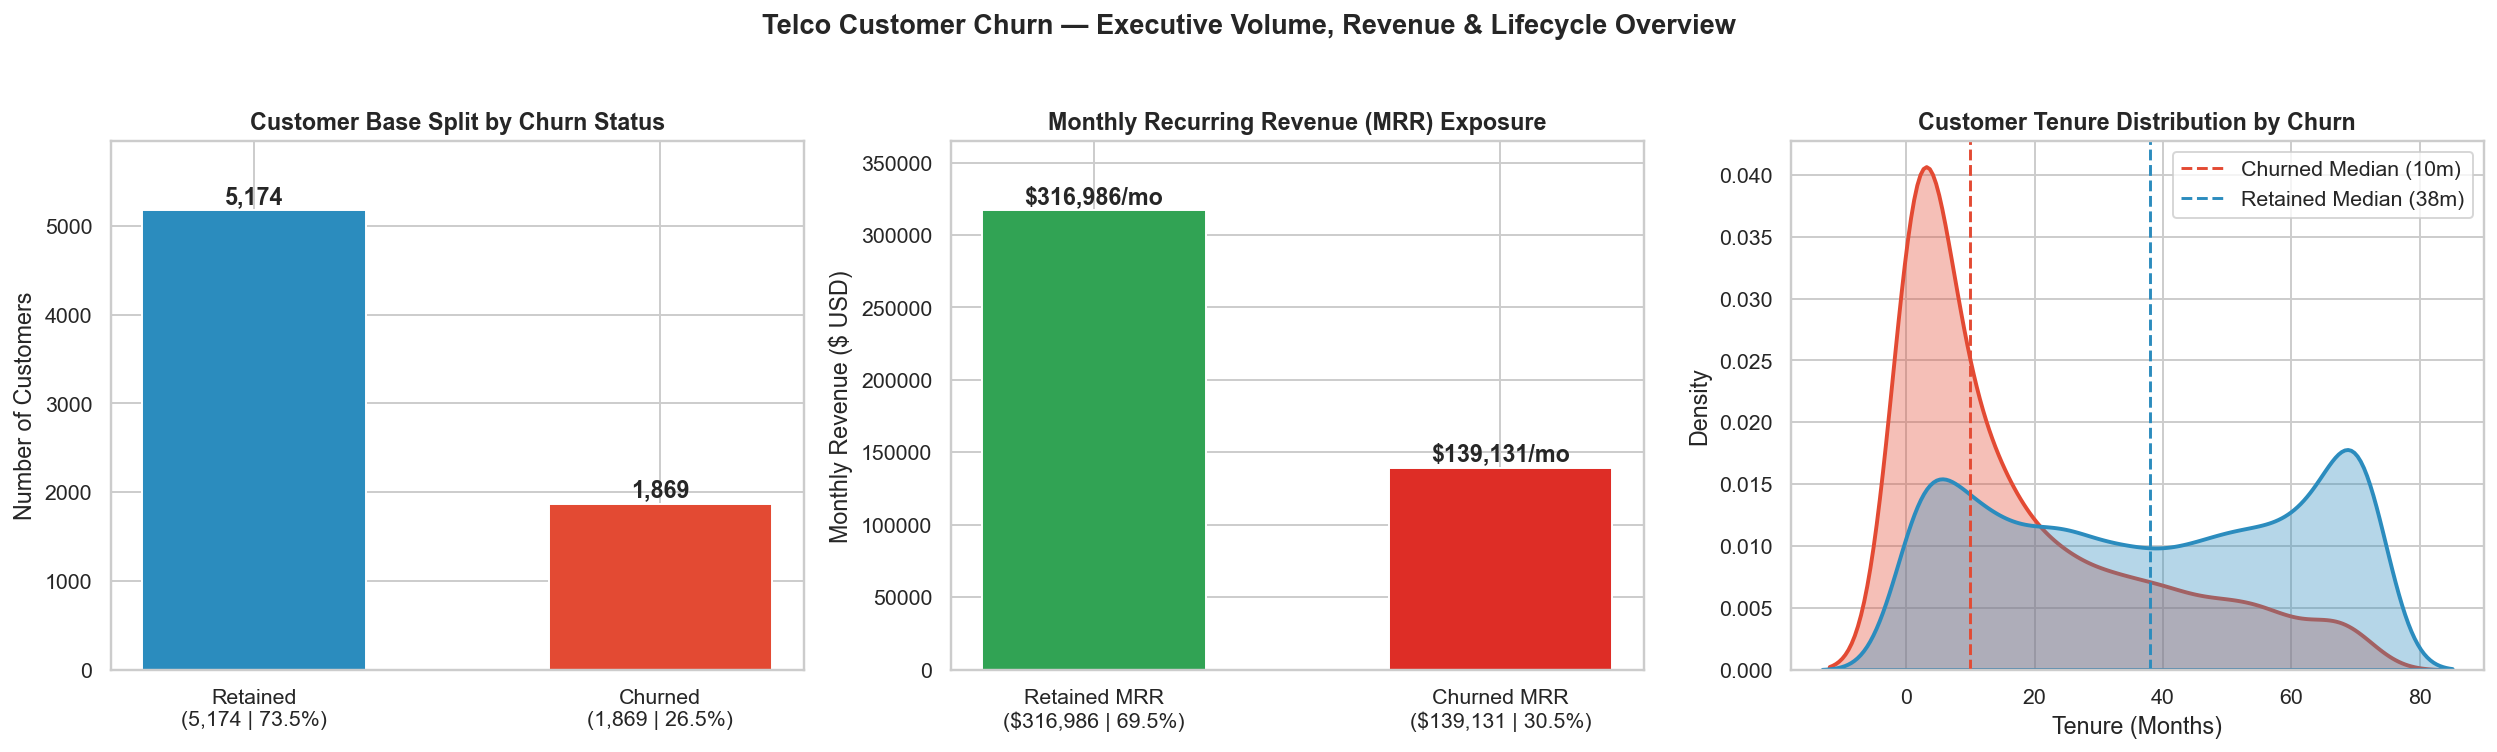

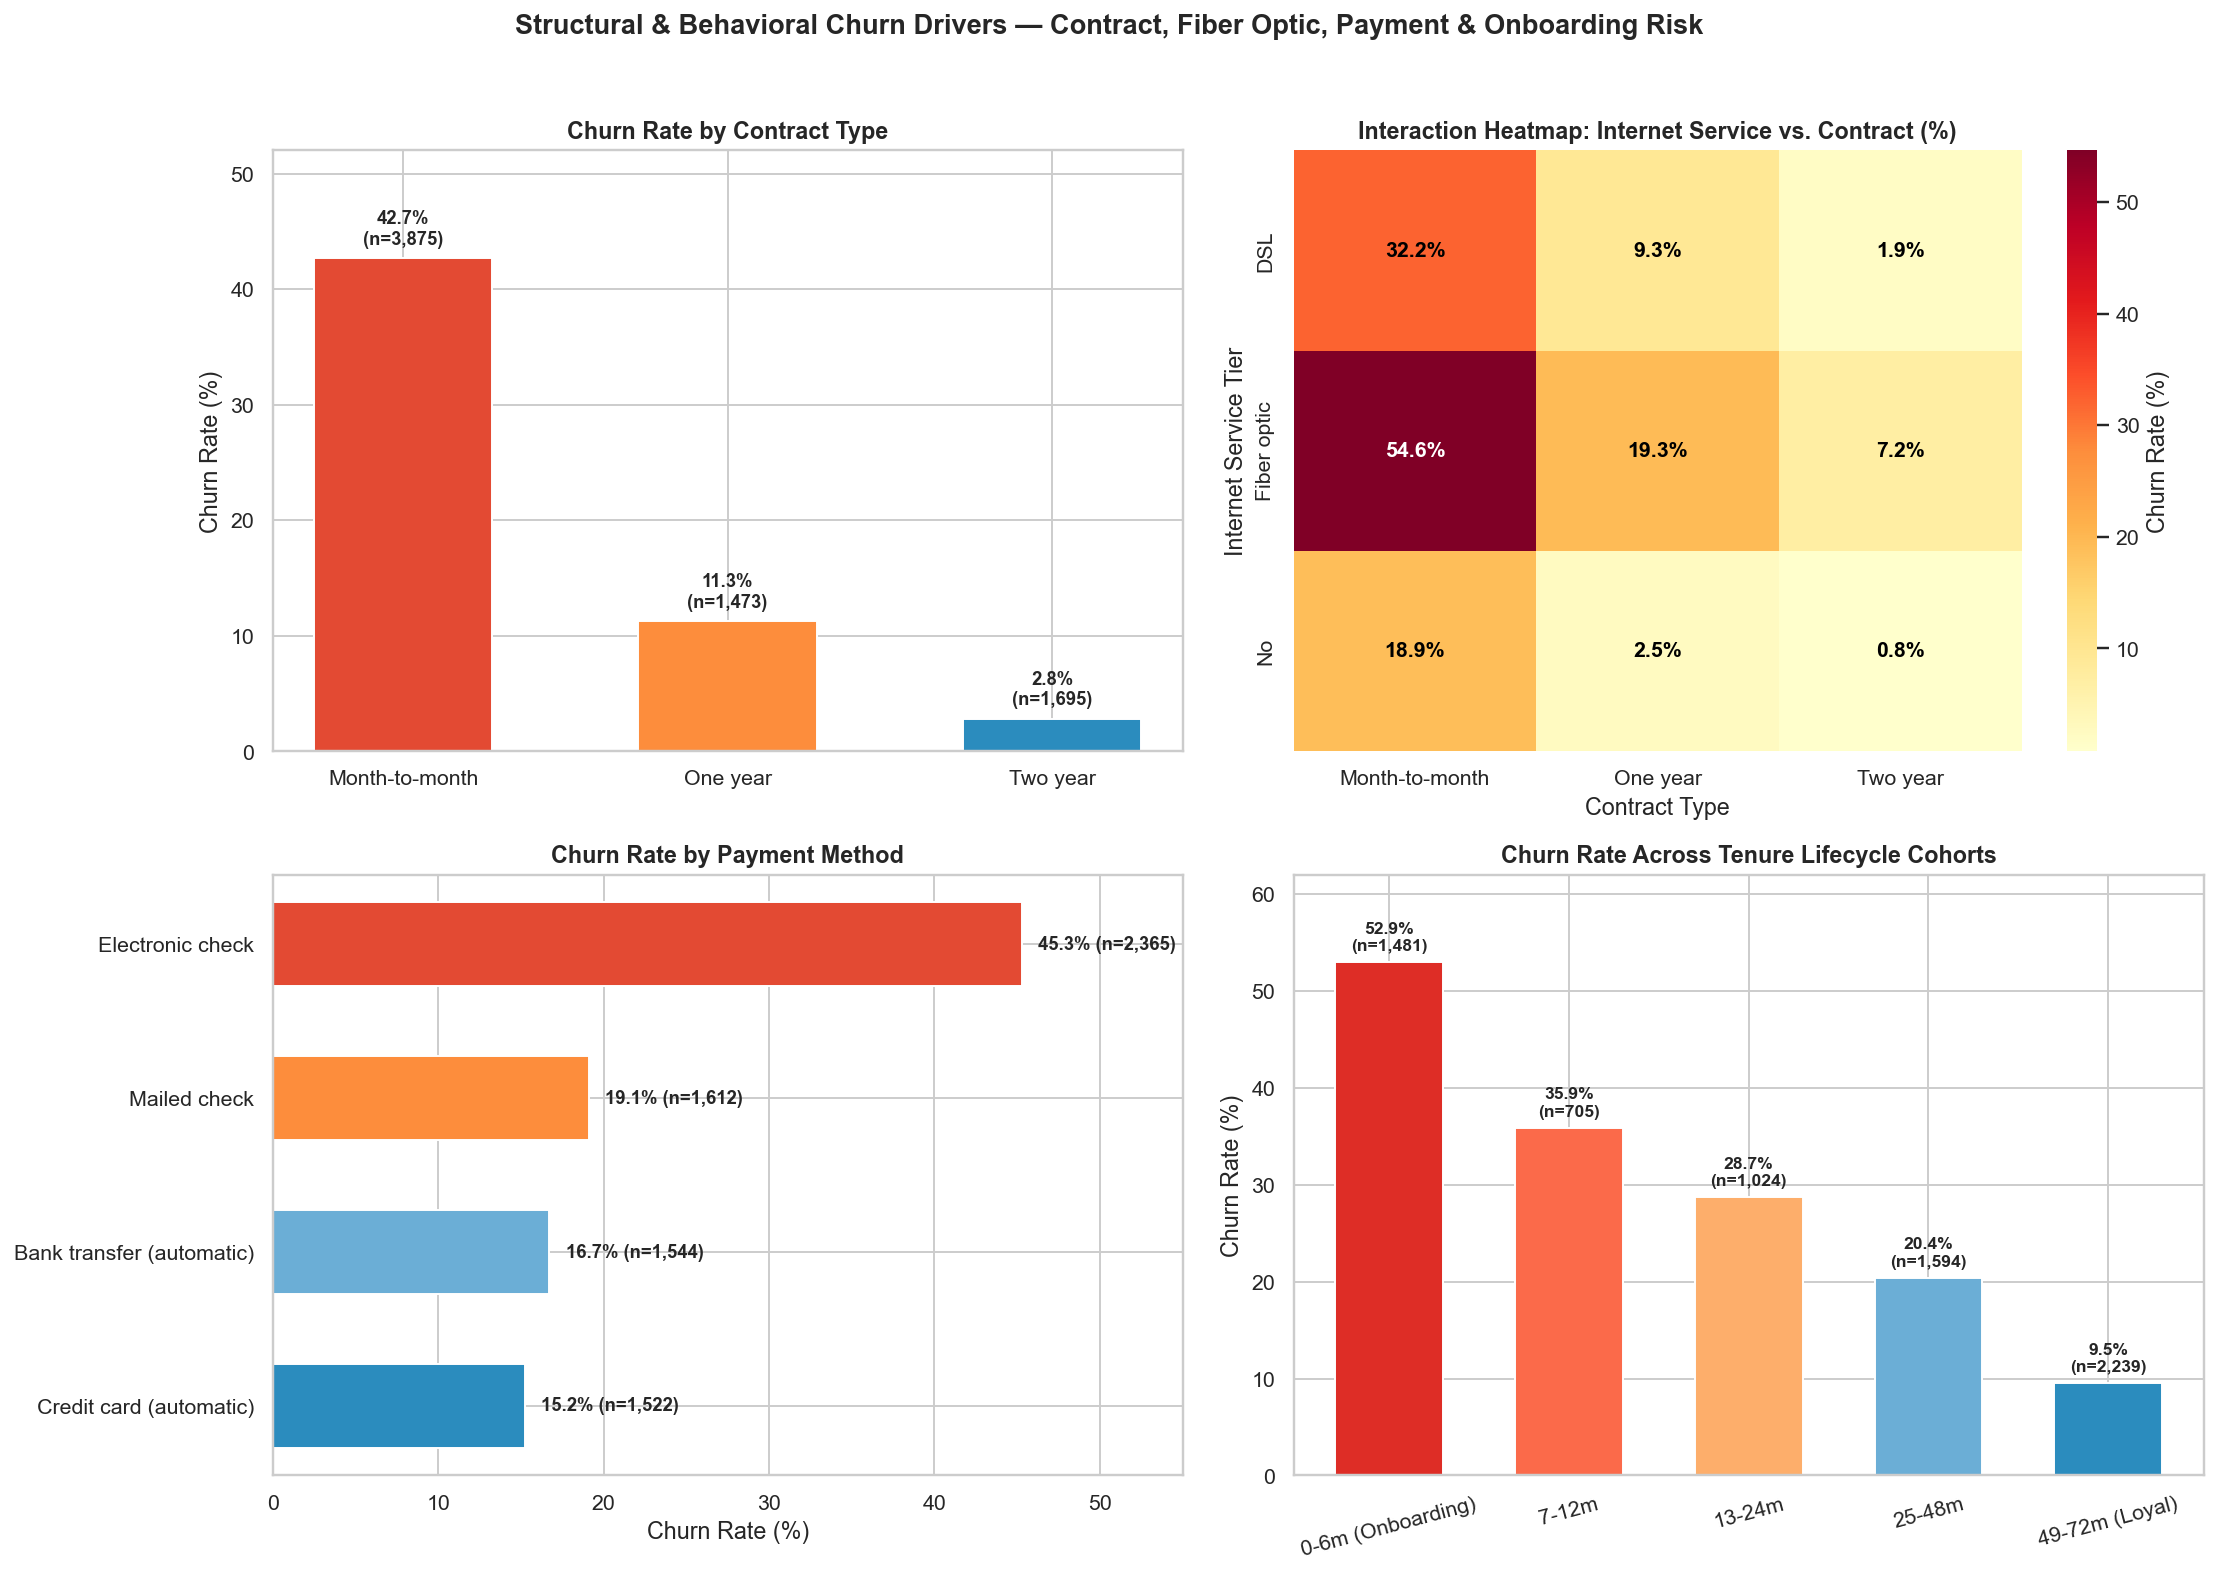

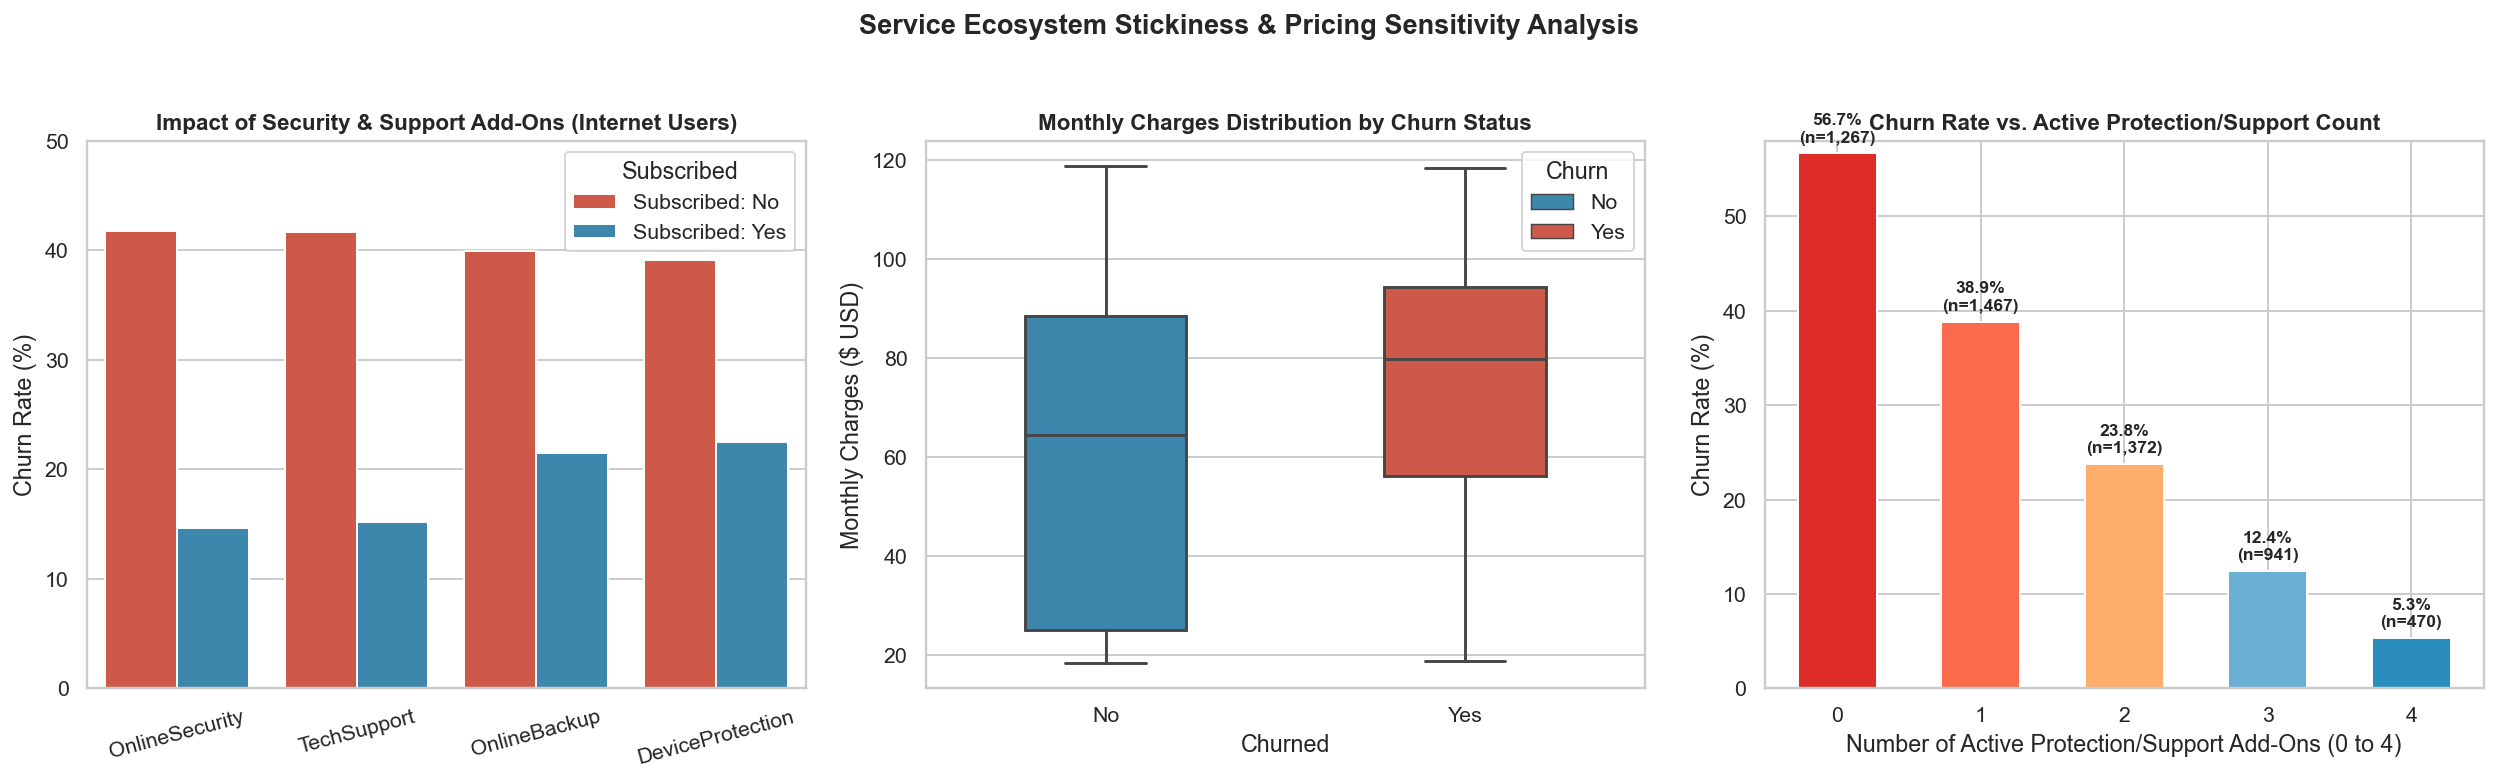

In [3]:
from IPython.display import Image, display

for fig_name in [
    '01_target_and_revenue_exposure.png',
    '02_contract_internet_payment_matrix.png',
    '03_addon_services_and_pricing_dynamics.png',
]:
    display(Image(filename=f'../artifacts/reports/figures/{fig_name}'))

**Key Visual Insights from EDA**:
1. **Contract Commitment**: `Month-to-month` customers churn at **42.71%** (`$120,847/mo` MRR lost — **86.9%** of all lost revenue), compared to **11.27%** for `One year` and **2.83%** for `Two year` contracts.
2. **Fiber Optic & Unprotected Internet Risk**: `Fiber optic` subscribers pay `$91.50/mo` on average and churn at **41.89%** (`54.6%` when on Month-to-month contracts). Furthermore, the **1,765** Fiber optic users without `OnlineSecurity` and `TechSupport` churn at **55.01%**.
3. **Payment Friction**: `Electronic check` users churn at **45.29%**, nearly `3x` higher than automatic credit card (**15.24%**) or automatic bank transfer (**16.71%**).
4. **Onboarding Cliff**: Customers in their first **0–6 months** churn at **52.94%**, with median churner tenure at **10.0 months** vs. **38.0 months** for retained users.

## 4. Leakage-Free Preprocessing, Model Comparison & Retention Engine

Champion Model: logistic_regression
Champion Test Metrics: {
  "roc_auc": 0.8533,
  "roc_auc_95ci": [
    0.8212,
    0.874
  ],
  "pr_auc": 0.661,
  "f1_score": 0.625,
  "precision": 0.4979,
  "recall": 0.8393,
  "accuracy": 0.7332,
  "brier_score": 0.1636,
  "optimal_threshold": 0.38,
  "expected_business_cost": 29850.0,
  "confusion_matrix": {
    "tn": 540,
    "fp": 237,
    "fn": 45,
    "tp": 235
  }
}


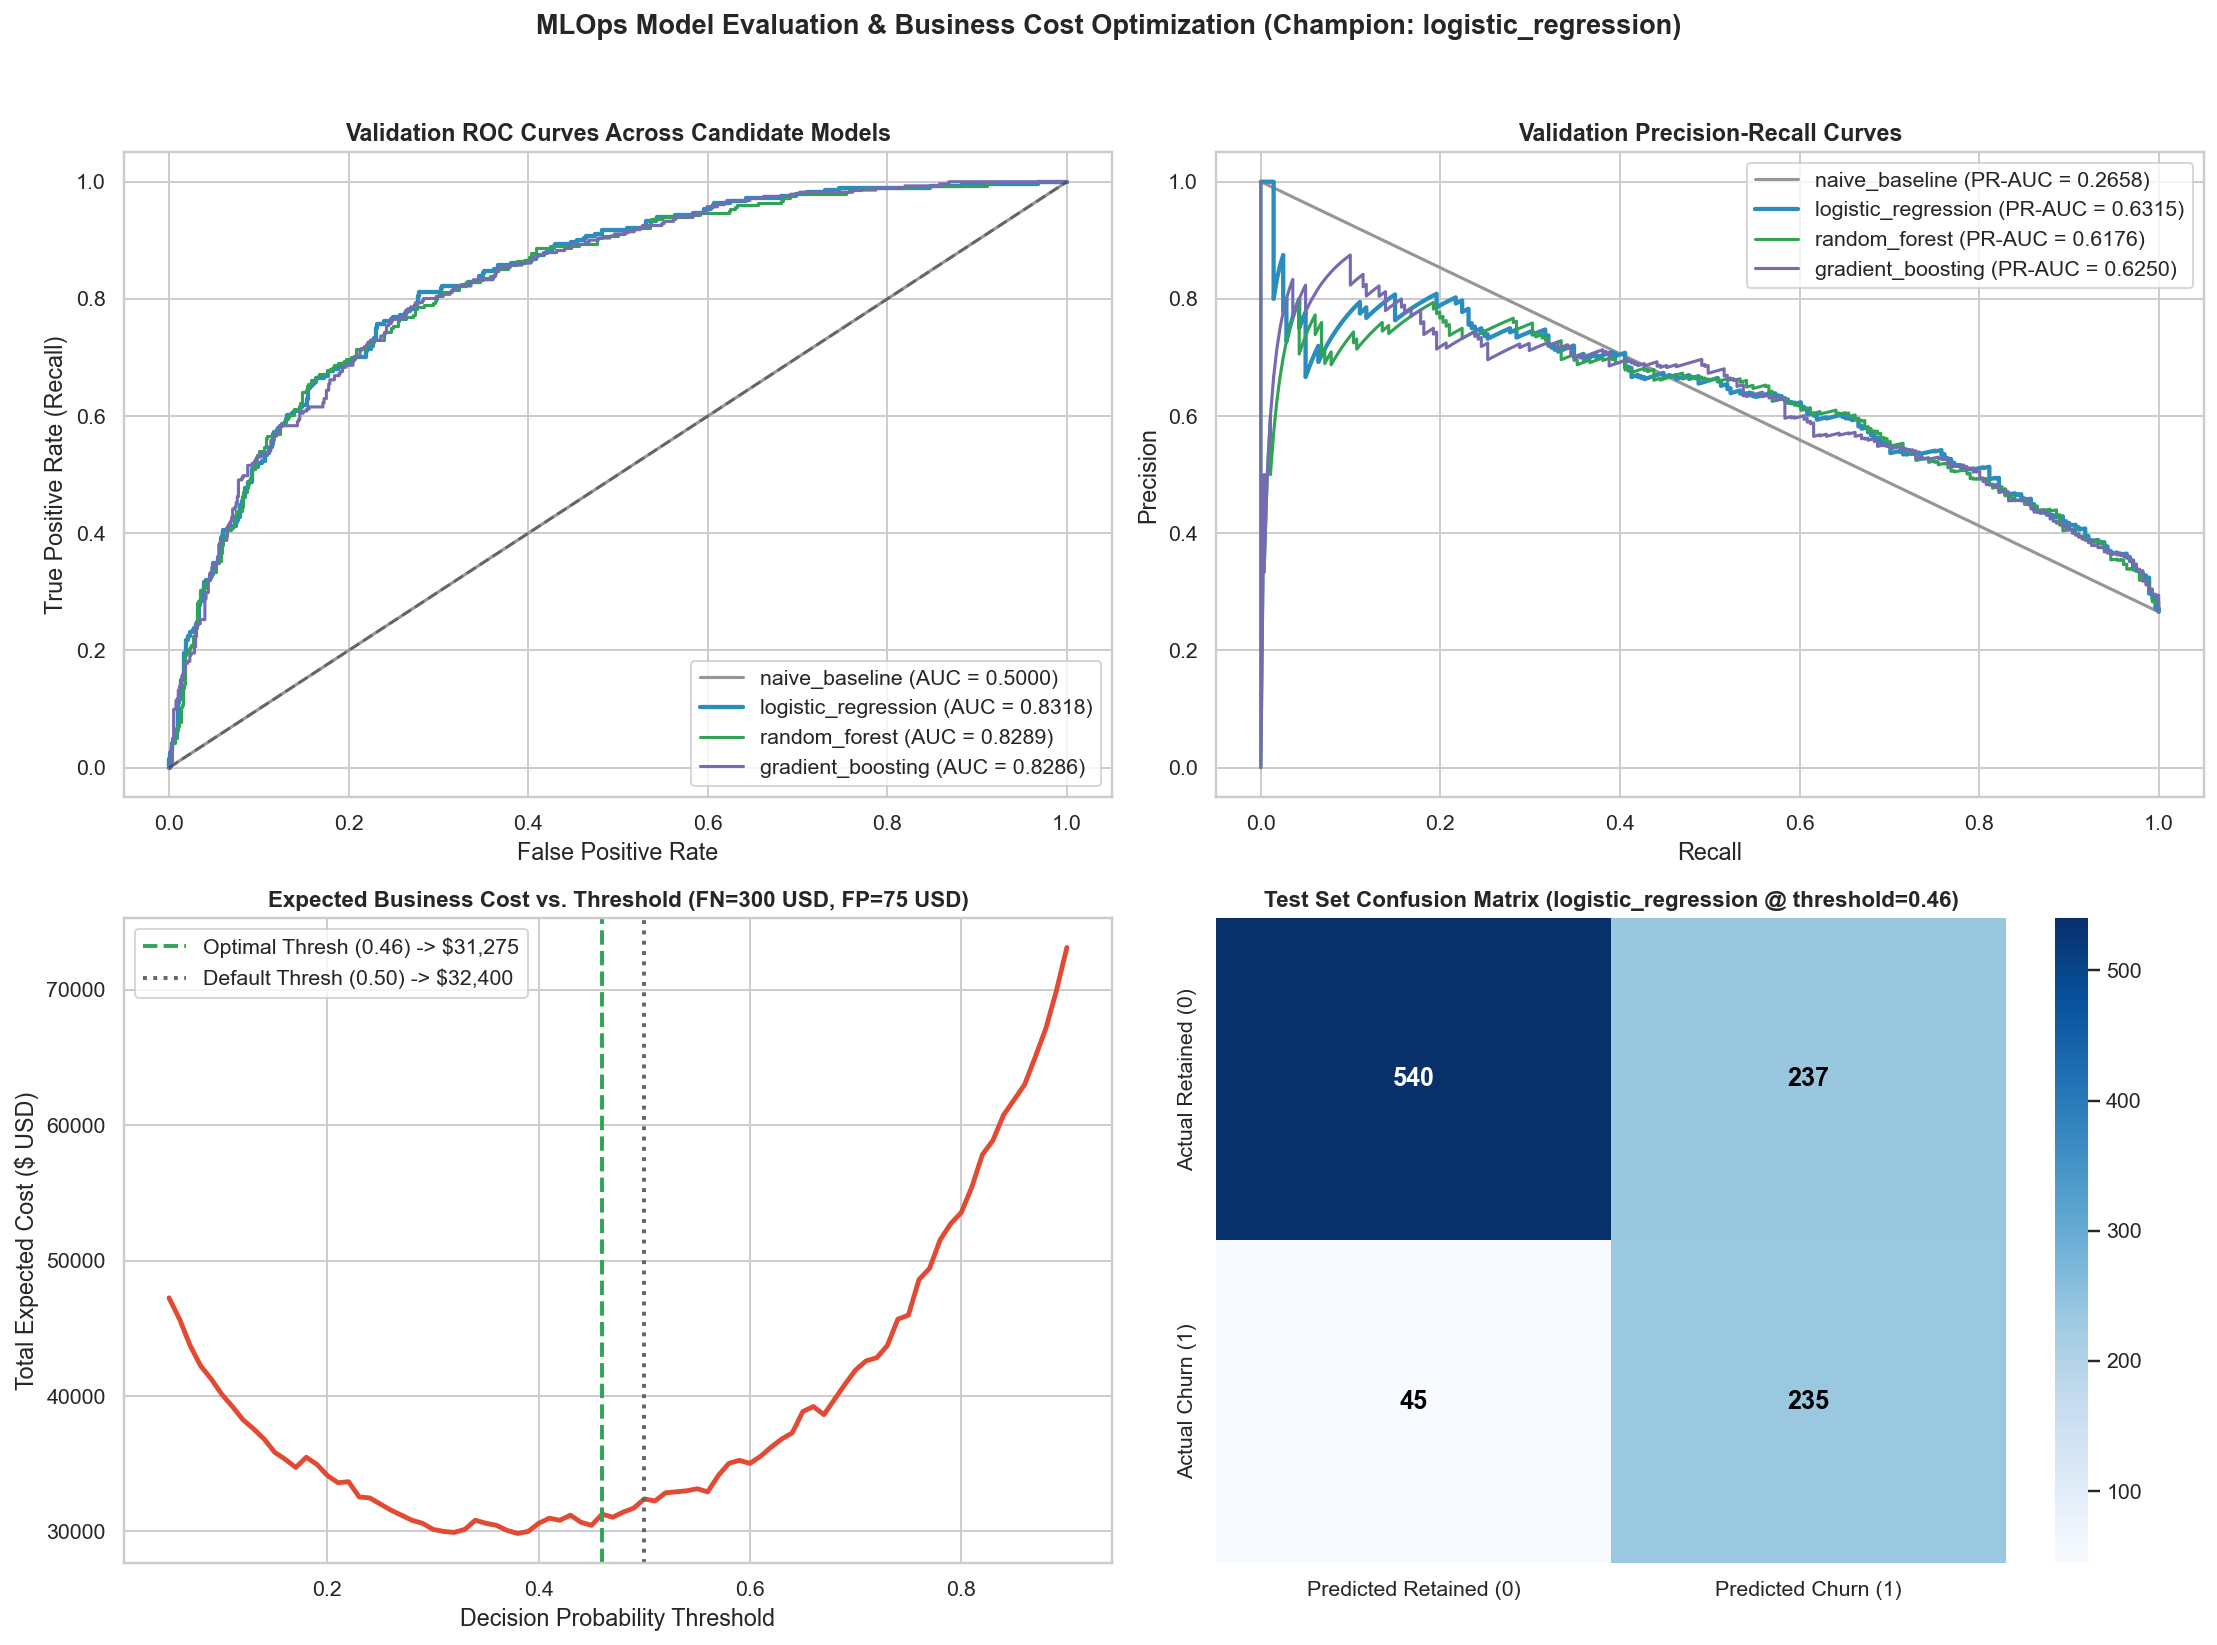

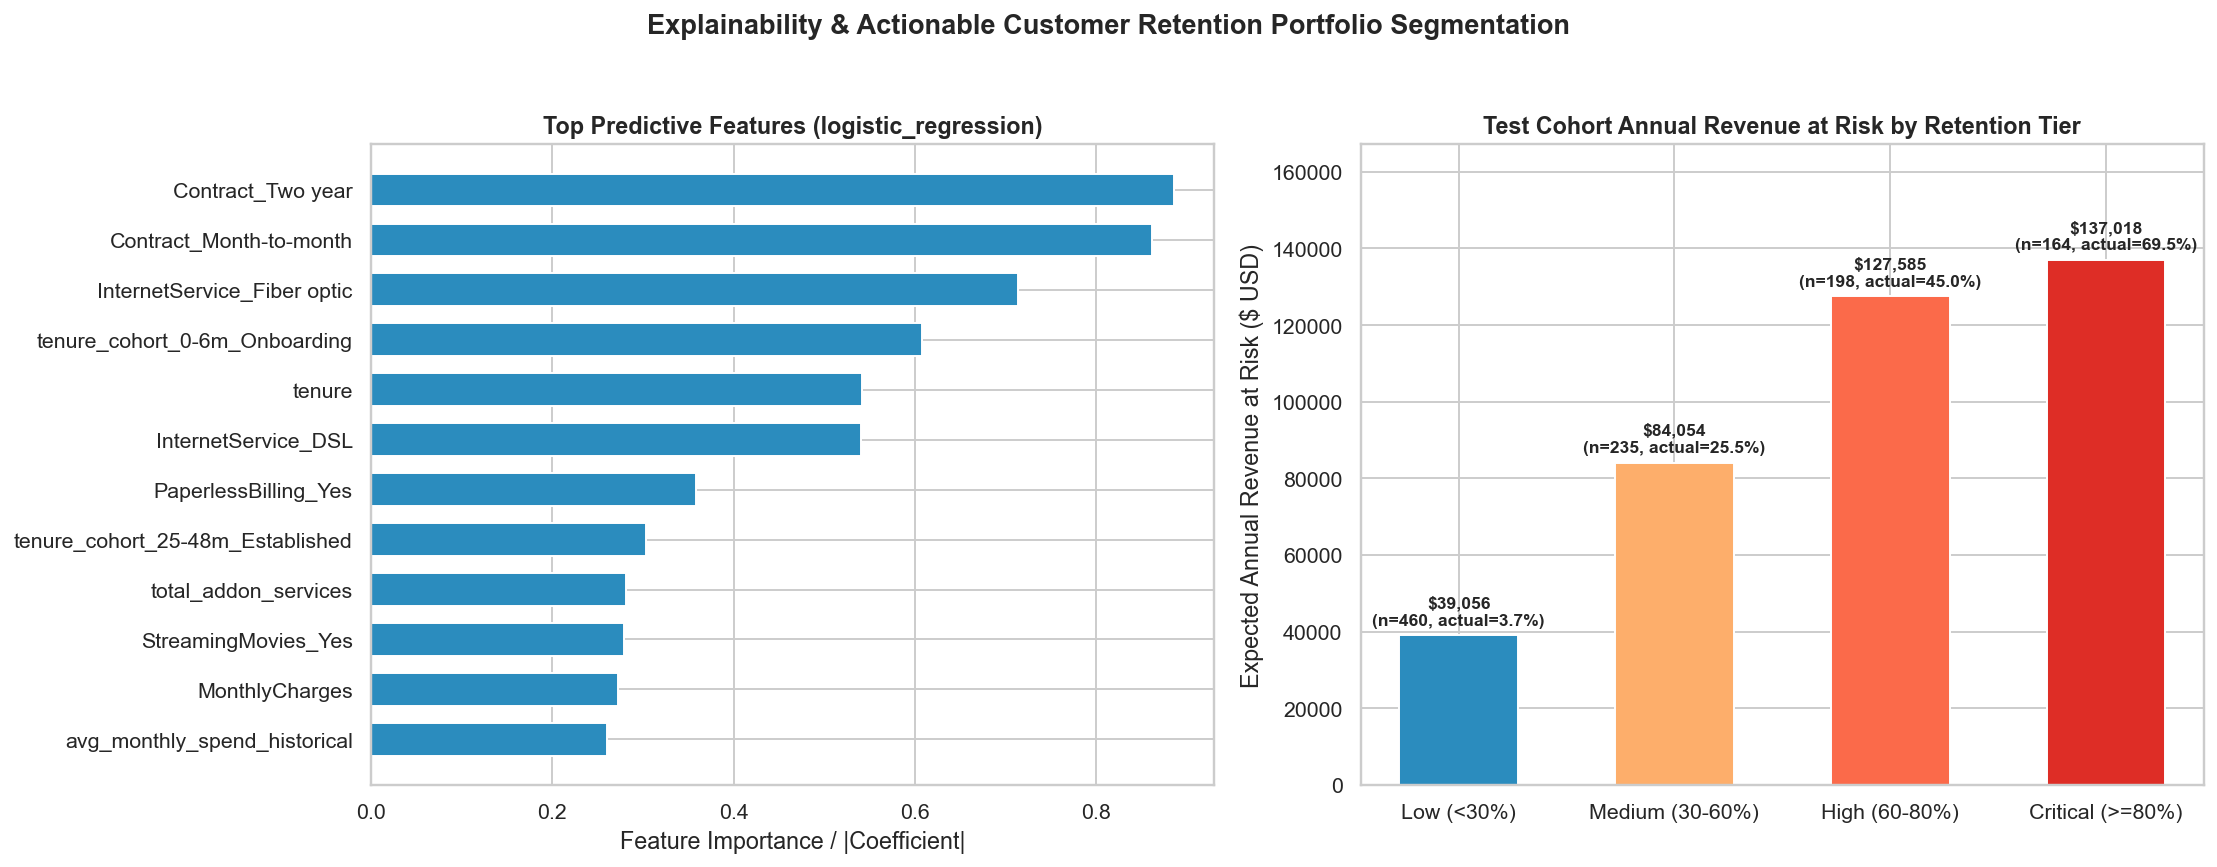

In [4]:
import json

with open('../artifacts/reports/evaluation_metrics.json') as f:
    eval_report = json.load(f)

print('Champion Model:', eval_report['champion_model'])
print('Champion Test Metrics:', json.dumps(eval_report['champion_test_metrics'], indent=2))
display(Image(filename='../artifacts/reports/figures/04_model_comparison_and_business_roi.png'))
display(Image(filename='../artifacts/reports/figures/05_feature_importance_and_retention_tiers.png'))

### Q&A
- **What is the core business problem in the Telco Customer Churn dataset?**
  High-value subscribers (`$74.44/mo` mean bill) are churning early (`10.0` months median tenure), costing **$139,130.85/month** (`$1,669,570.20/year` ARR) or **30.50%** of total monthly recurring revenue.
- **How were anomalies and data leakage prevented during preprocessing?**
  The 11 blank `TotalCharges` records were verified to be new signups (`tenure == 0`) and set to `0.0`. The dataset was stratified-split into Train (`4,929`), Validation (`1,057`), and Test (`1,057`) **before** fitting `SimpleImputer`, `StandardScaler`, and `OneHotEncoder`.

### Data Analysis Key Findings
- **Month-to-Month & Fiber Optic Concentration**: `Month-to-month` contracts exhibit a **42.71%** churn rate (`3,875` customers, accounting for **86.86%** of all lost MRR), and `Fiber optic` customers without `OnlineSecurity` or `TechSupport` (`1,765` customers) churn at **55.01%**.
- **Service Ecosystem Stickiness**: Internet subscribers with `0` protection/support add-ons churn at **56.7%**, whereas those with `1`, `2`, `3`, and `4` protection/support add-ons drop monotonically to **38.9%**, **23.8%**, **12.4%**, and **5.3%**.
- **Onboarding Vulnerability & Payment Friction**: Customers in months `0–6` churn at **52.94%**, and `Electronic check` payers churn at **45.29%** compared to **15.24%** for automatic credit card payers.
- **Model & Retention Performance**: The champion `logistic_regression` model achieves a held-out Test ROC-AUC of **0.8533** (`95% CI: [0.8212, 0.8740]`), PR-AUC of **0.6610**, and **83.93% Recall** (`235/280` churners caught). Its **Critical (`>=80%`)** and **High (`60–80%`)** risk tiers capture **$264,602.54/year** in expected ARR at risk across `362` test-set customers (whose actual observed churn rates are **69.51%** and **44.95%**, vs. only **3.70%** in the Low-risk tier).

### Insights or Next Steps
- **Bundle Free 6-Month Security & Tech Support for New Fiber Optic Signups**: Target the `1,765` unprotected Fiber optic subscribers (`55.01%` churn) with complimentary `OnlineSecurity` + `TechSupport` trials during the critical `0–6 month` onboarding window (`52.94%` churn) and a `$5–$10/mo` Auto-Pay enrollment credit.
- **Deploy Real-Time Retention Scoring via the FastAPI Service**: Use the `/predict` and `/predict/batch` endpoints (`uvicorn churn_engine.api.main:app --port 8000`) to trigger automated CSM outreach for `Critical` tier accounts (`>=80%` probability) with contract-upgrade incentives capped at 25% of each customer's expected ARR at risk.